In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
from scipy import stats
import sys
sys.path.append("/glade/work/smagahey/UCSB/codes/paper1_new/paper1/python_packages")
from myutils.composite_functions import select_events, var_composites, get_masks

## Parameters

In [2]:
# Region boxes [lat_min, lat_max, lon_min, lon_max]
n3   = [-5, 5, 210, 270]  # Nino3
n34  = [-5, 5, 190, 240]  # Nino3.4
n4   = [-5, 5, 160, 210]
pac  = [-5, 5, 120, 280]
regbox = [-40, 40, 90, 300]

# Year ranges
PI_YEARS   = slice(None, 29)   # first 30 years of PI period (index 0-28 → 29 years)
FUT_YEARS  = slice(None, 29)   # first 30 years of future period

## Load data

In [3]:
# Heat budget terms
ds_hb_hist = xr.open_dataset("/glade/work/smagahey/UCSB/codes/paper1_new/paper1/hb_analysis/hist_corrQ_hb_terms.nc")
ds_hb_fut  = xr.open_dataset("/glade/work/smagahey/UCSB/codes/paper1_new/paper1/hb_analysis/fut_corrQ_hb_terms.nc")

lat = ds_hb_fut['lat']
lon = ds_hb_fut['lon']

var_names = [
    "Qp", "ekU", "ekV", "eddyU", "eddyV",
    "UmdTpdx", "VmdTpdy", "upwelling", "eddyvert",
    "thermocline", "dTpdt"
]

vars_hist = {var: ds_hb_hist[var] for var in var_names}
vars_fut  = {var: ds_hb_fut[var]  for var in var_names}

# NPMM indices
dsnpi  = xr.open_dataset('/glade/work/smagahey/UCSB/codes/paper1_new/paper1/NPMM_analysis/pi_npmm_e3sm1.nc')
dsnfut = xr.open_dataset('/glade/work/smagahey/UCSB/codes/paper1_new/paper1/NPMM_analysis/fut_npmm_e3sm1.nc')

xmcapi  = dsnpi['X_MCA_pi']
xmcafut = dsnfut['X_MCA_fut']

## Compute seasonal means

In [4]:
def seasonal_mean(da, season):
    """Average over a DJF/MAM/JJA/SON season, grouping by year."""
    return da.sel(time=da.time.dt.season == season).groupby('time.year').mean('time')

# --- PI ---
# Predictors: MAM and JJA NPMM  →  (member, year)
npmm_mam_pi = seasonal_mean(xmcapi, 'MAM')
npmm_jja_pi = seasonal_mean(xmcapi, 'JJA')

# Target: SON heat budget  →  (member, year, lat, lon)
# MAM/JJA both precede SON within the same calendar year, so no year offset needed
budget_son_pi = {term: seasonal_mean(vars_hist[term], 'SON') for term in var_names}

# --- Future ---
npmm_mam_fut = seasonal_mean(xmcafut, 'MAM')
npmm_jja_fut = seasonal_mean(xmcafut, 'JJA')

budget_son_fut = {term: seasonal_mean(vars_fut[term], 'MAM') for term in var_names}

# Sanity check — shapes should all be (n_members, n_years)
print("PI   MAM NPMM shape:", npmm_mam_pi.shape)
print("PI   JJA NPMM shape:", npmm_jja_pi.shape)
print("PI   SON Qp shape:  ", budget_son_pi['Qp'].shape)
print("Fut  MAM NPMM shape:", npmm_mam_fut.shape)
print("Fut  JJA NPMM shape:", npmm_jja_fut.shape)
print("Fut  SON Qp shape:  ", budget_son_fut['Qp'].shape)

PI   MAM NPMM shape: (15, 30)
PI   JJA NPMM shape: (15, 30)
PI   SON Qp shape:   (15, 30, 80, 210)
Fut  MAM NPMM shape: (15, 30)
Fut  JJA NPMM shape: (15, 30)
Fut  SON Qp shape:   (15, 30, 80, 210)


## Regression function

In [5]:
def compute_seasonal_regression(npmm_season, field_season):
    """
    Pool across ensemble members and regress field onto NPMM index.

    Parameters
    ----------
    npmm_season  : (member, year)            – NPMM index for predictor season
    field_season : (member, year, lat, lon)  – heat budget term for target season

    Returns
    -------
    reg_map, corr_map, p_map  – each (lat, lon)
    """
    n_mem, n_year = npmm_season.shape
    npmm_pooled  = npmm_season.values.reshape(-1)                                          # (member*year,)
    field_pooled = field_season.values.reshape(n_mem * n_year,
                                               len(field_season.lat),
                                               len(field_season.lon))                      # (member*year, lat, lon)

    reg_map  = np.zeros((len(field_season.lat), len(field_season.lon)))
    corr_map = np.zeros_like(reg_map)
    p_map    = np.zeros_like(reg_map)

    for i in range(len(field_season.lat)):
        for j in range(len(field_season.lon)):
            y = field_pooled[:, i, j]
            # Skip grid points with all NaN (land/mask)
            valid = np.isfinite(npmm_pooled) & np.isfinite(y)
            if valid.sum() < 10:
                reg_map[i, j] = np.nan
                corr_map[i, j] = np.nan
                p_map[i, j] = np.nan
            else:
                slope, _, r, p, _ = stats.linregress(npmm_pooled[valid], y[valid])
                reg_map[i, j]  = slope
                corr_map[i, j] = r
                p_map[i, j]    = p

    return reg_map, corr_map, p_map

## Per-member regression & PI → FUT change significance (rank-sum)

In [6]:
def compute_regression_change_significance(npmm_pi, field_pi, npmm_fut, field_fut):
    """
    Per-member NPMM regression slopes computed separately for PI and Future,
    then a rank-sum (Mann-Whitney U) test on whether the slope distributions
    differ between the two (unpaired) ensembles.

    npmm_pi, npmm_fut   : (member, year)
    field_pi, field_fut : (member, year, lat, lon)

    Returns:
      diff_map : ensemble-mean-slope change, FUT - PI (lat, lon) -- for reference
      p_map    : rank-sum p-value for whether the PI vs FUT per-member slope
                 distributions differ (lat, lon)
    """
    def per_member_slopes(npmm_season, field_season):
        n_mem, n_year = npmm_season.shape
        n_lat, n_lon = len(field_season.lat), len(field_season.lon)
        slopes = np.full((n_mem, n_lat, n_lon), np.nan)

        for m in range(n_mem):
            npmm_m  = npmm_season.values[m, :]
            field_m = field_season.values[m, :, :, :]
            for i in range(n_lat):
                for j in range(n_lon):
                    y     = field_m[:, i, j]
                    valid = np.isfinite(npmm_m) & np.isfinite(y)
                    if valid.sum() < 10:
                        continue
                    slope, _, _, _, _ = stats.linregress(npmm_m[valid], y[valid])
                    slopes[m, i, j] = slope
        return slopes

    slopes_pi  = per_member_slopes(npmm_pi, field_pi)
    slopes_fut = per_member_slopes(npmm_fut, field_fut)

    n_lat, n_lon = slopes_pi.shape[1], slopes_pi.shape[2]
    diff_map = np.nanmean(slopes_fut, axis=0) - np.nanmean(slopes_pi, axis=0)

    p_map = np.full((n_lat, n_lon), np.nan)
    for i in range(n_lat):
        for j in range(n_lon):
            a = slopes_pi[:, i, j]
            b = slopes_fut[:, i, j]
            a = a[np.isfinite(a)]
            b = b[np.isfinite(b)]
            if len(a) < 3 or len(b) < 3:
                continue
            try:
                # rank-sum test (Mann-Whitney U), unpaired, two-sided
                _, p_map[i, j] = stats.mannwhitneyu(a, b, alternative='two-sided')
            except ValueError:
                # occurs if all values identical in both groups
                p_map[i, j] = np.nan

    return diff_map, p_map

## Run regressions

Two predictors × two periods = 4 sets of maps per heat budget term.

| Key | Predictor | Target | Lag |
|-----|-----------|--------|-----|
| `'MAM'` | MAM NPMM | SON budget | ~6 months |
| `'JJA'` | JJA NPMM | SON budget | ~3 months |

In [7]:
results_pi  = {}   # results_pi[term]['MAM'] and results_pi[term]['JJA']
results_fut = {}

for term in var_names:
    print(f"Computing regressions for {term}...")

    # PI
    results_pi[term] = {
        'MAM': compute_seasonal_regression(
            npmm_mam_pi.isel(year=PI_YEARS),
            budget_son_pi[term].isel(year=PI_YEARS)
        ),
        'JJA': compute_seasonal_regression(
            npmm_jja_pi.isel(year=PI_YEARS),
            budget_son_pi[term].isel(year=PI_YEARS)
        ),
    }

    # Future
    results_fut[term] = {
        'MAM': compute_seasonal_regression(
            npmm_mam_fut.isel(year=FUT_YEARS),
            budget_son_fut[term].isel(year=FUT_YEARS)
        ),
        'JJA': compute_seasonal_regression(
            npmm_jja_fut.isel(year=FUT_YEARS),
            budget_son_fut[term].isel(year=FUT_YEARS)
        ),
    }

print("Done.")

Computing regressions for Qp...
Computing regressions for ekU...
Computing regressions for ekV...
Computing regressions for eddyU...
Computing regressions for eddyV...
Computing regressions for UmdTpdx...
Computing regressions for VmdTpdy...
Computing regressions for upwelling...
Computing regressions for eddyvert...
Computing regressions for thermocline...
Computing regressions for dTpdt...
Done.


## Significance of the PI → FUT change (rank-sum on per-member slopes, per term/lag)

In [8]:
print("Computing PI vs FUT change significance (rank-sum on per-member slopes)...")

sig_change = {}
lag_predictors = {
    'MAM': (npmm_mam_pi, npmm_mam_fut),
    'JJA': (npmm_jja_pi, npmm_jja_fut),
}

for term in var_names:
    print(f"  {term}...")
    sig_change[term] = {}
    for lag, (npmm_pi_lag, npmm_fut_lag) in lag_predictors.items():
        _, p_map = compute_regression_change_significance(
            npmm_pi_lag.isel(year=PI_YEARS),
            budget_son_pi[term].isel(year=PI_YEARS),
            npmm_fut_lag.isel(year=FUT_YEARS),
            budget_son_fut[term].isel(year=FUT_YEARS),
        )
        sig_change[term][lag] = p_map

print("Done.")

Computing PI vs FUT change significance (rank-sum on per-member slopes)...
  Qp...


/glade/derecho/scratch/smagahey/tmp/ipykernel_92103/3545331521.py:37: RuntimeWarning: Mean of empty slice
  diff_map = np.nanmean(slopes_fut, axis=0) - np.nanmean(slopes_pi, axis=0)


  ekU...
  ekV...
  eddyU...
  eddyV...
  UmdTpdx...
  VmdTpdy...
  upwelling...
  thermocline...
  dTpdt...
Done.


## Plot: 2×2 panels (PI MAM | PI JJA | Fut MAM | Fut JJA)

In [9]:
import string

def plot_multiterm_summary(terms, results_pi, results_fut, sig_change, lats, lons, lag='MAM'):
    """
    sig_change : dict[term][lag] -> p_map (lat, lon), rank-sum (Mann-Whitney U)
                 p-value for whether the PI vs FUT per-member regression slopes
                 differ at each grid point. The same stippling mask is drawn on
                 both the PI and Future columns in a row, since significance here
                 is a property of the change, not of either period alone.
    """
    term_labels = {
        'ekU_total':   'ekU',
        'ekV_total':   'ekV',
        'eddyV':       'eddyV',
        'thermocline': 'Thermocline',
        'dTpdt':       'dTp/dt',
    }
    n_terms = len(terms)
    fig = plt.figure(figsize=(16, 4 * n_terms))
    from matplotlib.gridspec import GridSpec
    gs = GridSpec(n_terms, 3, figure=fig,
                  hspace=0.35, wspace=0.1,
                  width_ratios=[1, 1, 0.04])

    panel_labels = iter(string.ascii_lowercase)  # a, b, c, ...
    lon2d, lat2d = np.meshgrid(lons, lats)

    for row, term in enumerate(terms):
        data_pi  = results_pi[term][lag]
        data_fut = results_fut[term][lag]
        vmax = max(np.nanpercentile(np.abs(d[0]), 95) for d in [data_pi, data_fut])
        if vmax == 0 or np.isnan(vmax):
            vmax = 1.0

        # significance of the PI -> FUT change (rank-sum on per-member slopes);
        # same mask applied to both the PI and Future columns
        p_map    = sig_change[term][lag]
        sig_mask = p_map[::2, ::2] < 0.1 #alpha

        map_axes = []
        for col, (reg_map, corr_map, _pooled_p) in enumerate([data_pi, data_fut]):
            ax = fig.add_subplot(gs[row, col],
                                 projection=ccrs.PlateCarree(central_longitude=180))
            map_axes.append(ax)
            im = ax.contourf(
                lons, lats, reg_map,
                levels=np.linspace(-vmax, vmax, 21),
                cmap='RdBu_r', extend='both',
                transform=ccrs.PlateCarree()
            )
            ax.scatter(lon2d[::2, ::2][sig_mask], lat2d[::2, ::2][sig_mask],
                       c='gray', s=1, transform=ccrs.PlateCarree())
            ax.coastlines()
            ax.add_feature(cfeature.LAND, facecolor='lightgray')
            ax.set_extent([regbox[2], regbox[3], regbox[0], regbox[1]], crs=ccrs.PlateCarree())
            gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5)
            gl.top_labels    = False
            gl.right_labels  = False
            gl.bottom_labels = (row == n_terms - 1)   # lon labels only on bottom row
            gl.left_labels   = (col == 0)             # lat labels only on left column

            if row == 0:
                title = f'PI: {lag} NPMM -> SON' if col == 0 else f'Future: {lag} NPMM -> SON'
                ax.set_title(title, fontsize=20, fontweight='bold')

            label = next(panel_labels)
            ax.text(0.02, 0.95, f'({label})', transform=ax.transAxes,
                     fontsize=16, fontweight='bold', va='top', ha='left',
                     bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=1.5))

        map_axes[0].text(-0.1, 0.5, term_labels.get(term, term),
                 va='center', ha='right', rotation=90, fontsize=20, fontweight='bold',
                 transform=map_axes[0].transAxes)

        cbar_ax = fig.add_subplot(gs[row, 2])
        cb = fig.colorbar(im, cax=cbar_ax, orientation='vertical', extend='both')
        cb.set_ticks([-vmax, 0, vmax])
        cb.set_ticklabels([f'{-vmax*1e3:.1f}', '0', f'{vmax*1e3:.1f}'])
        cb.set_label(f'{term_labels.get(term, term)} (\u00d710$^{{-3}}$ \u00b0C month$^{{-1}}$)', fontsize=14)

    fig.subplots_adjust(left=0.12)
    fig.suptitle('MAM heat budget regression onto NPMM', fontsize=20, y=.92)
    plt.savefig('regression_npmm_hb_summary_MAM.png', dpi=150, bbox_inches='tight')
    plt.show()

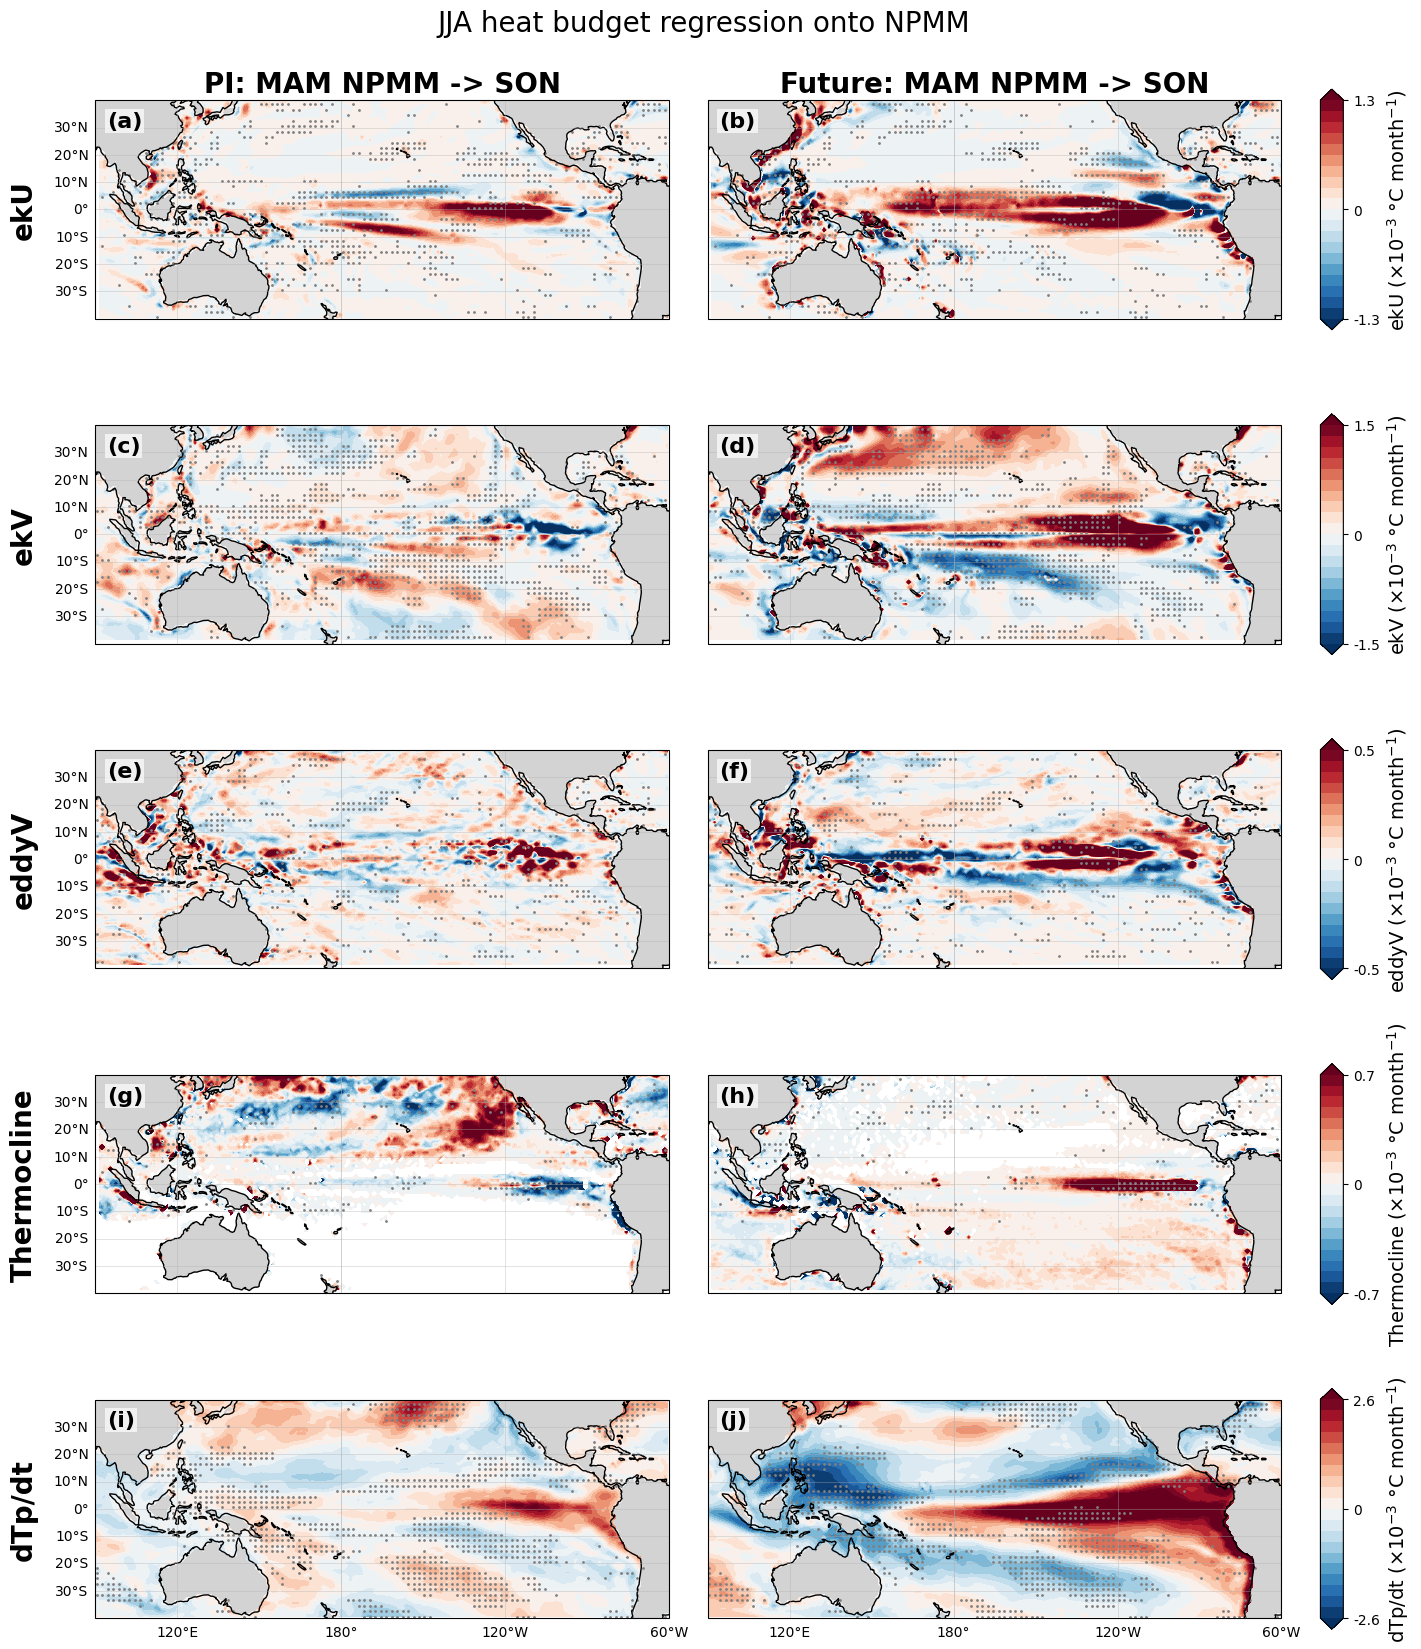

In [10]:
# Initialize combined keys first
for results in [results_pi, results_fut]:
    results['ekU_total'] = {}
    results['ekV_total'] = {}

# Then compute combined regression maps
for results in [results_pi, results_fut]:
    for lag in ['MAM', 'JJA']:
        results['ekU_total'][lag] = (
            results['ekU'][lag][0], #+ results['UmdTpdx'][lag][0],
            results['ekU'][lag][1],
            results['ekU'][lag][2]
        )
        results['ekV_total'][lag] = (
            results['ekV'][lag][0] , #+ results['VmdTpdy'][lag][0]
            results['ekV'][lag][1],
            results['ekV'][lag][2]
        )

# Combined terms reuse the same underlying field (the extra term is commented
# out above), so their change-significance is the same as the base term's.
sig_change['ekU_total'] = sig_change['ekU']
sig_change['ekV_total'] = sig_change['ekV']

plot_multiterm_summary(
    terms=['ekU_total', 'ekV_total', 'eddyV', 'thermocline', 'dTpdt'],
    results_pi=results_pi,
    results_fut=results_fut,
    sig_change=sig_change,
    lats=lat,
    lons=lon,
    lag='MAM'
)

In [11]:
term, lag = 'eddyV', 'MAM'   # pick wherever the visual difference looks biggest

# find array indices near a specific lat/lon, e.g. 0N, 150W
i = int(np.argmin(np.abs(lat.values - 2)))
j = int(np.argmin(np.abs(((lon.values - 190)))))

# recompute per-member slopes just at this one point for inspection
def slopes_at_point(npmm_season, field_season, i, j):
    n_mem = npmm_season.shape[0]
    out = []
    for m in range(n_mem):
        x = npmm_season.values[m, :]
        y = field_season.values[m, :, i, j]
        valid = np.isfinite(x) & np.isfinite(y)
        if valid.sum() < 10:
            out.append(np.nan); continue
        slope, *_ = stats.linregress(x[valid], y[valid])
        out.append(slope)
    return np.array(out)

s_pi  = slopes_at_point(npmm_mam_pi.isel(year=PI_YEARS),  budget_son_pi[term].isel(year=PI_YEARS),  i, j)
s_fut = slopes_at_point(npmm_mam_fut.isel(year=FUT_YEARS), budget_son_fut[term].isel(year=FUT_YEARS), i, j)

print('PI  slopes:', np.round(s_pi, 3))
print('FUT slopes:', np.round(s_fut, 3))
print('PI  mean/std:', np.nanmean(s_pi), np.nanstd(s_pi))
print('FUT mean/std:', np.nanmean(s_fut), np.nanstd(s_fut))
print('rank-sum p:', stats.mannwhitneyu(s_pi[np.isfinite(s_pi)], s_fut[np.isfinite(s_fut)], alternative='two-sided')[1])

PI  slopes: [ 0.     0.    -0.     0.     0.001 -0.     0.001  0.     0.001 -0.
  0.     0.    -0.    -0.    -0.   ]
FUT slopes: [ 0.001 -0.001 -0.001 -0.     0.    -0.     0.     0.    -0.002  0.002
 -0.001  0.003 -0.002 -0.002  0.002]
PI  mean/std: 0.00012363953464462888 0.0003679479742661136
FUT mean/std: -0.00019069752369664503 0.0013676393009933745
rank-sum p: 0.3400858902842717


In [12]:
i5N = int(np.argmin(np.abs(lat.values - 5)))
print(lat.values[i5N])  # confirms what you actually landed on

4.5
